In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [7]:
df = pd.read_csv('Base_de_Datos_dynamic_pricing.csv')

In [8]:
df.head()

,Number_of_Riders,Number_of_Drivers,Location_Category,Customer_Loyalty_Status,Number_of_Past_Rides,Average_Ratings,Time_of_Booking,Vehicle_Type,Expected_Ride_Duration,Historical_Cost_of_Ride
0,90,45,Urban,Silver,13,4.47,Night,Premium,90,284.257273
1,58,39,Suburban,Silver,72,4.06,Evening,Economy,43,173.874753
2,42,31,Rural,Silver,0,3.99,Afternoon,Premium,76,329.795469
3,89,28,Rural,Regular,67,4.31,Afternoon,Premium,134,470.201232
4,78,22,Rural,Regular,74,3.77,Afternoon,Economy,149,579.681422


In [9]:
print(df['Customer_Loyalty_Status'].value_counts())
print(df.groupby('Customer_Loyalty_Status')['Expected_Ride_Duration'].describe())

Customer_Loyalty_Status
Silver     367
Regular    320
Gold       313
Name: count, dtype: int64
                         count        mean        std   min    25%    50%  \
Customer_Loyalty_Status                                                     
Gold                     313.0  101.603834  50.167887  10.0  60.00  105.0   
Regular                  320.0  100.565625  49.344246  11.0  58.75  101.0   
Silver                   367.0   97.016349  48.158831  10.0  60.00   98.0   

                           75%    max  
Customer_Loyalty_Status                
Gold                     148.0  180.0  
Regular                  141.5  180.0  
Silver                   137.5  180.0  


In [10]:
gold    = df.loc[df['Customer_Loyalty_Status'] == 'Gold',    'Expected_Ride_Duration'].dropna()
regular = df.loc[df['Customer_Loyalty_Status'] == 'Regular', 'Expected_Ride_Duration'].dropna()

In [11]:
n1, n2 = len(gold), len(regular)
s1, s2 = gold.var(ddof=1), regular.var(ddof=1)
print(f"n Gold={n1}, var Gold={s1:.3f}")
print(f"n Regular={n2}, var Regular={s2:.3f}")

n Gold=313, var Gold=2516.817
n Regular=320, var Regular=2434.855


In [12]:
for name, grp in [('Gold', gold), ('Regular', regular)]:
    stat, p = stats.shapiro(grp)
    print(f"Shapiro-Wilk {name}: W={stat:.4f}, p={p:.4e}")

Shapiro-Wilk Gold: W=0.9442, p=1.6884e-09
Shapiro-Wilk Regular: W=0.9520, p=1.0062e-08


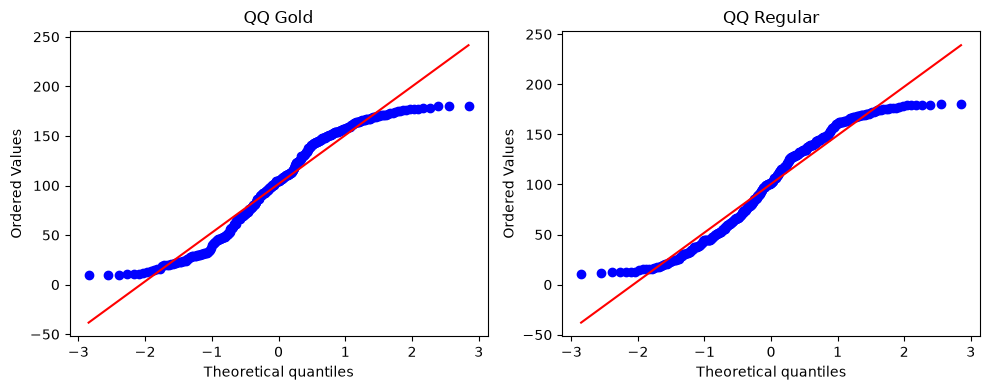

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10,4))
stats.probplot(gold,    dist="norm", plot=axes[0]); axes[0].set_title("QQ Gold")
stats.probplot(regular, dist="norm", plot=axes[1]); axes[1].set_title("QQ Regular")
plt.tight_layout(); plt.show()

In [14]:
if s1 >= s2:
    F = s1 / s2
    dfn, dfd = n1 - 1, n2 - 1
    var_mayor, var_menor = 'Gold', 'Regular'
else:
    F = s2 / s1
    dfn, dfd = n2 - 1, n1 - 1
    var_mayor, var_menor = 'Regular', 'Gold'

p_value = 2 * (1 - stats.f.cdf(F, dfn, dfd))  
p_value = min(p_value, 1.0)                     

print(f"F = {F:.4f}, gl_num={dfn}, gl_den={dfd}, p-valor (dos colas) = {p_value:.4e}")
alpha = 0.05
print("Rechazar H0" if p_value < alpha else "No rechazar H0")

F = 1.0337, gl_num=312, gl_den=319, p-valor (dos colas) = 7.6859e-01
No rechazar H0


/tmp/ipykernel_41256/2006375367.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df[df['Customer_Loyalty_Status'].isin(['Gold','Regular'])],


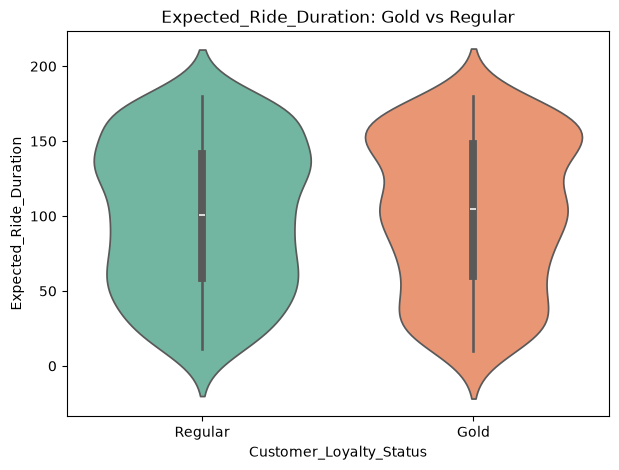

In [16]:
plt.figure(figsize=(7,5))
sns.violinplot(data=df[df['Customer_Loyalty_Status'].isin(['Gold','Regular'])],
               x='Customer_Loyalty_Status', y='Expected_Ride_Duration',
               inner='box', palette='Set2')
plt.title("Expected_Ride_Duration: Gold vs Regular")
plt.show()

## Análisis de resultados: prueba F de Fisher para la igualdad de varianzas

### 1. Planteamiento del problema

Se quiere determinar si la **varianza** de `Expected_Ride_Duration` (duración esperada del viaje, en minutos) difiere entre dos grupos de clientes según su estado de fidelidad: **Gold** y **Regular**. A diferencia de una prueba de medias, aquí el interés está en la **dispersión** o variabilidad de la duración de los viajes, no en su valor promedio.

Las hipótesis estadísticas planteadas son:

- **H₀:** `σ²_Gold = σ²_Regular` (las varianzas poblacionales son iguales).
- **H₁:** `σ²_Gold ≠ σ²_Regular` (las varianzas poblacionales son diferentes).

Se trabaja con un nivel de significancia **α = 0.05** y un contraste bilateral, porque la pregunta no especifica de antemano cuál grupo debe tener mayor varianza.

### 2. Análisis descriptivo

| Grupo | n | Media | Desv. estándar | Varianza | Mín. | Q1 | Mediana | Q3 | Máx. |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| Gold | 313 | 101.604 | 50.168 | 2516.817 | 10 | 60.00 | 105.0 | 148.0 | 180 |
| Regular | 320 | 100.566 | 49.344 | 2434.855 | 11 | 58.75 | 101.0 | 141.5 | 180 |

Los grupos son de tamaño muy similar (313 y 320 observaciones), lo que hace que la comparación de varianzas esté bien balanceada. Las medias son casi idénticas (diferencia aproximada de 1.04 minutos, alrededor del 1 %), mientras que las varianzas muestrales difieren en solo **81.96 minutos²**, es decir, cerca del **3.3 %** de la varianza menor. Las desviaciones estándar (50.17 vs. 49.34 minutos) y los cuartiles también son muy parecidos; ambos grupos cubren el mismo rango aproximado (10–180 minutos) y presentan una dispersión visualmente similar en el diagrama de violín. En conjunto, la descripción sugiere que la variabilidad de la duración esperada es parecida en los dos grupos.

### 3. Justificación de la aplicación de la prueba F

La prueba F de Fisher es adecuada en este caso por las siguientes razones:

- **La variable es cuantitativa:** `Expected_Ride_Duration` se mide en minutos y admite el cálculo de medias, desviaciones y varianzas.
- **Se comparan dos grupos independientes:** un cliente pertenece a Gold o a Regular, no a ambos, y las observaciones corresponden a viajes distintos. No hay datos pareados ni medidas repetidas.
- **El objetivo es comparar dispersión:** la prueba F contrasta directamente el cociente de dos varianzas poblacionales, que es exactamente la pregunta planteada.
- **Existe un estadístico con distribución conocida:** bajo H₀ y los supuestos del modelo, el cociente

  $$F = \frac{s^2_{Gold}}{s^2_{Regular}}$$

  sigue una distribución **F de Fisher** con `n_Gold − 1` grados de libertad en el numerador y `n_Regular − 1` grados de libertad en el denominador. Esto permite calcular el p-valor de forma exacta bajo normalidad.
- **Los tamaños muestrales son grandes y equilibrados:** con 313 y 320 observaciones, la distribución del estadístico es estable y la comparación no está dominada por diferencias de tamaño entre grupos.

Para el contraste bilateral se ubica la varianza mayor en el numerador, de modo que el estadístico sea mayor o igual que 1; luego el p-valor se obtiene duplicando el área de la cola superior de la distribución F. Con los datos observados:

$$F = \frac{2516.817}{2434.855} = 1.0337$$

con **312** grados de libertad en el numerador y **319** en el denominador. Los valores críticos al 5 % bilateral son aproximadamente **0.8015** y **1.2473**; como `F = 1.0337` cae dentro de esa región de aceptación, la conclusión coincide con la del p-valor.

### 4. Supuestos de la prueba F y su verificación

La prueba F requiere, en sentido estricto:

1. **Independencia de las observaciones:** cada viaje debe ser independiente de los demás y los grupos deben ser mutuamente excluyentes. El conjunto de datos está formado por registros de viajes distintos y los estados de fidelidad separan a los clientes; se asume que el proceso de recolección fue aleatorio y sin observaciones repetidas. Este supuesto no se puede comprobar con una prueba estadística: depende del diseño del muestreo.
2. **Normalidad de la variable en cada población:** es el supuesto más importante para que el cociente de varianzas siga exactamente una distribución F.
3. **Muestreo aleatorio:** las observaciones deben provenir de muestras aleatorias de sus respectivas poblaciones.
4. **Escala de medición:** la variable debe ser cuantitativa, como en este caso.

Es importante notar que **la igualdad de varianzas no es un supuesto de la prueba F, sino la hipótesis que se está contrastando**. El supuesto crítico es la normalidad.

La normalidad se evaluó con la prueba de **Shapiro-Wilk**:

- Gold: `W = 0.9442`, `p = 1.6884 × 10⁻⁹`.
- Regular: `W = 0.9520`, `p = 1.0062 × 10⁻⁸`.

En ambos casos el p-valor es menor que 0.05, por lo que **se rechaza la hipótesis de normalidad estricta**. Los gráficos Q-Q muestran desviaciones principalmente en las colas, y la distribución presenta colas algo más ligeras que la normal (curtosis cercana a −1.2 en ambos grupos), con asimetrías leves (≈ −0.20 en Gold y ≈ −0.11 en Regular). Es decir, la forma de las dos distribuciones es muy parecida entre sí, aunque no sea exactamente normal.

### 5. Resultado de la prueba y decisión estadística

El procedimiento aplicado arroja:

- **Estadístico F:** 1.0337.
- **Grados de libertad:** 312 (numerador) y 319 (denominador).
- **p-valor bilateral:** 0.76859.
- **Nivel de significancia:** 0.05.

Como **p = 0.76859 > 0.05**, **no se rechaza H₀**. El cociente de varianzas observado está muy cerca de 1 y es perfectamente compatible con la variación aleatoria esperada si las varianzas poblacionales fueran iguales. Un intervalo de confianza aproximado del 95 % para el cociente `σ²_Gold / σ²_Regular` iría de **0.829 a 1.290**, e incluye el valor 1, lo que refuerza la misma conclusión.

### 6. Interpretación de los resultados

No existe evidencia estadística suficiente para afirmar que la variabilidad de la duración esperada de los viajes sea diferente entre los clientes Gold y Regular. La diferencia observada entre las varianzas muestrales (2516.817 vs. 2434.855) es pequeña en términos prácticos y puede atribuirse al error de muestreo. En otras palabras, ambos segmentos presentan una dispersión similar en el tiempo esperado de viaje: los viajes de los clientes Gold no son ni claramente más homogéneos ni claramente más variables que los de los clientes Regular.

Esta conclusión tiene una implicación práctica: si se realizan comparaciones de medias entre estos grupos (por ejemplo, una prueba t o un ANOVA), el supuesto de homogeneidad de varianzas parece razonable y no habría indicios de que la variabilidad difiera entre segmentos. Sin embargo, la igualdad de varianzas es una conclusión probabilística, no una prueba definitiva de que sean idénticas.

### 7. Robustez, limitaciones y recomendaciones

El resultado debe interpretarse con cautela porque el supuesto de normalidad no se cumple estrictamente. La prueba F es sensible a desviaciones de la normalidad, especialmente a colas pesadas y valores atípicos, aunque en este caso los tamaños muestrales son grandes (313 y 320), los grupos están equilibrados y las dos distribuciones tienen formas muy similares. Estas condiciones tienden a hacer que la prueba F sea relativamente robusta, pero no eliminan la limitación.

Como verificación complementaria se recomienda aplicar pruebas de varianza que no dependan de la normalidad, como **Levene**, **Brown-Forsythe** (Levene centrado en la mediana) o **Fligner-Killeen**. Al calcularlas sobre estos mismos datos, los resultados son consistentes con la conclusión anterior: Levene/Brown-Forsythe arroja `p ≈ 0.904` y Fligner-Killeen `p ≈ 0.566`; en ambos casos no se rechaza la igualdad de varianzas. Esto aporta evidencia adicional de que la diferencia observada no es significativa.

Otras recomendaciones:

- Revisar la presencia de valores atípicos o de registros extremos, ya que la prueba F puede verse afectada por ellos.
- Verificar que la selección de los viajes haya sido aleatoria y que no existan dependencias ocultas (por ejemplo, varios viajes del mismo cliente o del mismo período).
- Si el objetivo es comparar **medias** y no varianzas, usar preferentemente la prueba **t de Welch**, que no exige igualdad de varianzas y es más segura ante distribuciones no normales y tamaños muestrales desiguales.

